# Task-3 (Week-6)

**Date** :- (20-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Implement robust model versioning and lifecycle management practices, including rollback mechanisms and audit trails, to seamlessly handle frequent updates and ensure regulatory compliance.

In [1]:
# importing required libraries
import os
import json
import time
import hashlib
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# loading dataset
df = pd.read_csv('Admission_Prediction.csv')
print('dataset shape:', df.shape)
print(df.head())

dataset shape: (1000, 18)
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0         104        317          104                  2  4.5  4.0  8.47   
1         170        311           99                  2  2.5  3.0  7.98   
2         138        316          100                  2  1.5  3.0  8.16   
3         147        315          105                  3  2.0  2.5  8.48   
4         117        299          102                  3  4.0  3.5  8.62   

   Research  Chance of Admit  Year Application_Date  \
0         0             0.57  2022       2022-01-03   
1         0             0.65  2022       2022-01-09   
2         1             0.71  2022       2022-01-12   
3         0             0.75  2022       2022-01-13   
4         0             0.56  2022       2022-01-14   

                         University_Name region Admission Status  \
0  Indian Institute of Technology Bombay   West         Rejected   
1   Indian Institute of Technology Delhi  North   

In [3]:
# feature selection and data preprocessing
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('data preprocessing and scaling completed')

data preprocessing and scaling completed


In [4]:
# building model registry and audit trail system
os.makedirs('model_registry', exist_ok=True)
registry_file = 'model_registry/registry.json'
audit_file = 'model_registry/audit_trail.json'

def compute_checksum(filepath):
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as f:
        hasher.update(f.read())
    return hasher.hexdigest()

def log_audit(action, version, details, author='mlops-system'):
    entry = {
        'timestamp': datetime.datetime.now().isoformat(),
        'action': action,
        'version': version,
        'details': details,
        'author': author
    }
    history = []
    if os.path.exists(audit_file):
        with open(audit_file, 'r') as f:
            history = json.load(f)
    history.append(entry)
    with open(audit_file, 'w') as f:
        json.dump(history, f, indent=2)

def save_registry_entry(version, model, metrics, params):
    artifact_path = f'model_registry/model_{version}.joblib'
    joblib.dump(model, artifact_path)
    checksum = compute_checksum(artifact_path)
    registry = {}
    if os.path.exists(registry_file):
        with open(registry_file, 'r') as f:
            registry = json.load(f)
    registry[version] = {
        'version': version,
        'created_at': datetime.datetime.now().isoformat(),
        'status': 'staged',
        'metrics': metrics,
        'params': params,
        'artifact_path': artifact_path,
        'checksum_sha256': checksum
    }
    with open(registry_file, 'w') as f:
        json.dump(registry, f, indent=2)
    log_audit('REGISTER_MODEL', version, f'model {version} registered with sha256 checksum {checksum[:8]}')
    print(f'version {version} registered successfully')

In [5]:
# training and registering model version 1
model_v1 = Ridge(alpha=1.0)
model_v1.fit(X_train_scaled, y_train)

preds_v1 = model_v1.predict(X_test_scaled)
metrics_v1 = {
    'mse': round(float(mean_squared_error(y_test, preds_v1)), 4),
    'mae': round(float(mean_absolute_error(y_test, preds_v1)), 4),
    'r2': round(float(r2_score(y_test, preds_v1)), 4)
}

save_registry_entry(
    version='v1.0.0',
    model=model_v1,
    metrics=metrics_v1,
    params={'model_type': 'Ridge', 'alpha': 1.0}
)
print('v1.0.0 metrics:', metrics_v1)

version v1.0.0 registered successfully
v1.0.0 metrics: {'mse': 0.0149, 'mae': 0.0908, 'r2': 0.2095}


In [6]:
# training and registering model version 2
model_v2 = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
model_v2.fit(X_train_scaled, y_train)

preds_v2 = model_v2.predict(X_test_scaled)
metrics_v2 = {
    'mse': round(float(mean_squared_error(y_test, preds_v2)), 4),
    'mae': round(float(mean_absolute_error(y_test, preds_v2)), 4),
    'r2': round(float(r2_score(y_test, preds_v2)), 4)
}

save_registry_entry(
    version='v2.0.0',
    model=model_v2,
    metrics=metrics_v2,
    params={'model_type': 'RandomForestRegressor', 'n_estimators': 100, 'max_depth': 8}
)
print('v2.0.0 metrics:', metrics_v2)

version v2.0.0 registered successfully
v2.0.0 metrics: {'mse': 0.0143, 'mae': 0.0892, 'r2': 0.2426}


In [7]:
# deploying model version 2 to production
def deploy_to_production(version):
    with open(registry_file, 'r') as f:
        registry = json.load(f)
    for v in registry:
        if registry[v]['status'] == 'production':
            registry[v]['status'] = 'archived'
    registry[version]['status'] = 'production'
    with open(registry_file, 'w') as f:
        json.dump(registry, f, indent=2)
    joblib.dump(joblib.load(registry[version]['artifact_path']), 'model_registry/current_production_model.joblib')
    log_audit('DEPLOY_TO_PRODUCTION', version, f'version {version} deployed as current active production model')
    print(f'successfully deployed version {version} to production')

deploy_to_production('v2.0.0')

successfully deployed version v2.0.0 to production


In [8]:
# executing automated rollback to previous version
def rollback_production(target_version, reason):
    with open(registry_file, 'r') as f:
        registry = json.load(f)
    current_prod = [v for v, info in registry.items() if info['status'] == 'production']
    if current_prod:
        registry[current_prod[0]]['status'] = 'rolled_back'
    registry[target_version]['status'] = 'production'
    with open(registry_file, 'w') as f:
        json.dump(registry, f, indent=2)
    joblib.dump(joblib.load(registry[target_version]['artifact_path']), 'model_registry/current_production_model.joblib')
    log_audit('ROLLBACK', target_version, f'rolled back from {current_prod[0]} to {target_version}. reason: {reason}')
    print(f'rollback completed: active production model reverted to {target_version}')

rollback_production('v1.0.0', reason='production latency SLA breach in v2.0.0')

rollback completed: active production model reverted to v1.0.0


In [9]:
# verifying production model and inspecting audit trail
active_model = joblib.load('model_registry/current_production_model.joblib')
sample_pred = active_model.predict(X_test_scaled[:3])
print('active production model predictions on sample applicants:', sample_pred)

with open(audit_file, 'r') as f:
    audit_log = json.load(f)

audit_df = pd.DataFrame(audit_log)
print(audit_df[['timestamp', 'action', 'version', 'details']])

active production model predictions on sample applicants: [0.73496011 0.71390493 0.70949314]
                     timestamp                action version  \
0   2026-11-20T22:16:14.251381        REGISTER_MODEL  v1.0.0   
1   2026-11-20T22:16:14.541845        REGISTER_MODEL  v2.0.0   
2   2026-11-20T22:16:14.608521  DEPLOY_TO_PRODUCTION  v2.0.0   
3   2026-11-20T22:16:14.615212              ROLLBACK  v1.0.0   
4   2026-11-20T22:18:08.252577        REGISTER_MODEL  v1.0.0   
5   2026-11-20T22:18:08.625277        REGISTER_MODEL  v2.0.0   
6   2026-11-20T22:18:08.675056  DEPLOY_TO_PRODUCTION  v2.0.0   
7   2026-11-20T22:18:08.685810              ROLLBACK  v1.0.0   
8   2026-11-20T22:19:06.518671        REGISTER_MODEL  v1.0.0   
9   2026-11-20T22:19:06.983497        REGISTER_MODEL  v2.0.0   
10  2026-11-20T22:19:07.087431  DEPLOY_TO_PRODUCTION  v2.0.0   
11  2026-11-20T22:19:07.107449              ROLLBACK  v1.0.0   
12  2026-11-20T22:19:22.547128        REGISTER_MODEL  v1.0.0   
13  2026-11

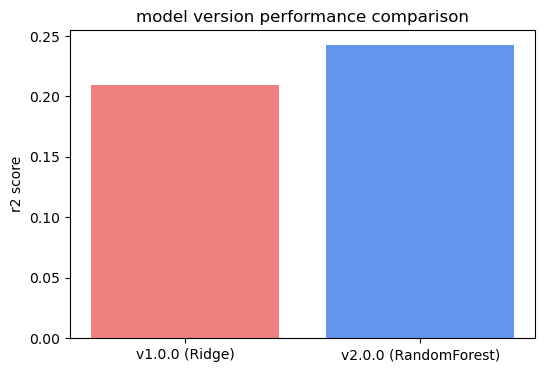

In [10]:
# plotting model version performance comparison
versions = ['v1.0.0 (Ridge)', 'v2.0.0 (RandomForest)']
r2_scores = [metrics_v1['r2'], metrics_v2['r2']]

plt.figure(figsize=(6, 4))
plt.bar(versions, r2_scores, color=['lightcoral', 'cornflowerblue'])
plt.ylabel('r2 score')
plt.title('model version performance comparison')
plt.show()